# S-T-D model fits and parameter uncertainties 

Grid search, followed by simulated annealing is used to fit the S-T-D model (see [FitSTD.py](../../modelling/FitSTD.py)).

We estimate parameter uncertainty for S-T-D model using bootstrapping from a grid search and plot the best fits

Contains:
- Best fits & uncertainty analysis from bootstrapping (Extended Data Figure 4i and Supplementary Note)
- Parameter sensitivity analysis (Supplementary Note)
- Plotting STD model applied to clonal data (Figure 1i-k,m, Extended Data Figure 4).


## Running fitting: 
### Finding best fits
To find best fits with simulated annealing run: [FitSTD.py](../../modelling/FitSTD.py):
```bash
#Comment out the model use
mode=1 #Use 2D
#mode=0 #Use 0D


#Males 
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.0 -1.0 0.5 0 ::: {-120..-101} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.5 -1.0 0.5 0 ::: {-140..-121} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.0  1.0 0.5 0 ::: {-160..-141} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.5  1.0 0.5 0 ::: {-180..-161} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 1.0  1.0 0.5 0 ::: {-200..-181} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.0 -1.0 0.5 2 ::: {-220..-201} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.5 -1.0 0.5 2 ::: {-240..-221} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.0  1.0 0.5 2 ::: {-260..-241} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 0.5  1.0 0.5 2 ::: {-280..-261} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 1.0  1.0 0.5 2 ::: {-300..-281} &

#Females
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.0 -1.0 0.5 0 ::: {-120..-101} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.5 -1.0 0.5 0 ::: {-140..-121} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.0  1.0 0.5 0 ::: {-160..-141} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.5  1.0 0.5 0 ::: {-180..-161} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 1.0  1.0 0.5 0 ::: {-200..-181} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.0 -1.0 0.5 2 ::: {-220..-201} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.5 -1.0 0.5 2 ::: {-240..-221} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.0  1.0 0.5 2 ::: {-260..-241} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 0.5  1.0 0.5 2 ::: {-280..-261} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 1.0  1.0 0.5 2 ::: {-300..-281} &

```

At the end to combine files run:
```bash
#Analyse simulations
python3.12 FitSTD.py -1000 1 0 M -2000 &
python3.12 FitSTD.py -1000 1 0 F -2000 &
```


### Estimating parameter uncertainty with grid search+bootstrapping
To estimate parameter uncertainty run: [FitSTD.py](../../modelling/FitSTD.py):

```bash
#Run bootstrapping
parallel --max-procs 50 python3.12 FitSTD.py {1} 1 $mode M 1000 0.0 1.0 0.5 0 1.0 ::: {0..12000} &
parallel --max-procs 50 python3.12 FitSTD.py {1} 1 $mode F 1000 0.0 1.0 0.5 0 1.0 ::: {0..12000} &


#Analyse simulations
python3.12 FitSTD.py -1000 1 0 M 1000 &
python3.12 FitSTD.py -1000 1 0 F 1000 &
```

In [ ]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle

sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")



from tissue import *
import tissplot as tplt
import matplotlib.path as mplPath
import datasets as ds 
import tiss_optimize as topt
import sim_model
import custom_metrics as cmet



#Metrics
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}

ll_dist_STD = {'dist': ['Slike.fullbasalCS', 'Slike.fullsupraCS',
                    'Tlike.fullbasalCS', 'Tlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS', 
                    'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_STD'}

ll_dist_SPD = {'dist': ['S4like.fullbasalCS', 'S4like.fullsupraCS',
                    'CPlike.fullbasalCS', 'CPlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS'], 
                    'dist_metric': 'lLL', 'name': 'll_SPD'}
T0 = 50
mets = [ll_dist_SPD, ll_dist_STD, ksdists, k1dists] 
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['basalCS', 'S4like.basalCS', 'S4like.supraCS', 'CPlike.basalCS', 'CPlike.supraCS', 'Dlike.basalCS', 'Dlike.supraCS',
               'Tlike.basalCS', 'Tlike.supraCS', 'Slike.basalCS', 'Slike.supraCS', 'S2like.basalCS', 'S2like.supraCS',
               'T3like.basalCS', 'T3like.supraCS', 'S2like.xfrac', 'Slike.xfrac', 'Tlike.xfrac', 'Dlike.xfrac',
               'S4like.lcd', 'T3like.lcd', 'CPlike.lcd', 'Dlike.lcd', 'Slike.lcd', 'Tlike.lcd', 'S2like.lcd',
               'S4like.pers', 'T3like.pers', 'CPlike.pers', 'Dlike.pers', 'Slike.pers', 'Tlike.pers', 'S2like.pers',
               'supraCS']


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


rcParams['axes.labelsize'] = 10
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] =  7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5
rcParams['axes.titlesize'] = 10


In [ ]:
'''  
    Getting best fits & parameter uncertainties from bootstrapping
'''


def boot_stats_STD(s0, met, best_fit):
    boot_stats = s0.boot_stats(met).T

    boot_stats['rhoS'] = best_fit['rhoS']
    boot_stats['tscale'] = -boot_stats[met + ':tscale']
    boot_stats['tau'] = 100
    boot_stats['CVd_S'] = best_fit['CVd_S']
    boot_stats['corrST'] = best_fit['corrST']
    boot_stats['corrTD'] = best_fit['corrTD']

    boot_stats['mu'] = ((boot_stats['q']-2)*boot_stats['rhoS']*boot_stats['tau'] + boot_stats['tau']*(1-boot_stats['rhoS']))/(boot_stats['rhoS']*(3-boot_stats['q']))#/boot_stats['tau']*boot_stats['tscale']
    boot_stats['rhoT1'] = boot_stats['tau']/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['rhoT2'] = boot_stats['tau']*(1-boot_stats['q'])/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['rhoD'] = boot_stats['mu']*(3-boot_stats['q'])/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['mu1'] = boot_stats['mu']
    boot_stats['mu'] = ((boot_stats['q']-2)*boot_stats['rhoS']*boot_stats['tau'] + boot_stats['tau']*(1-boot_stats['rhoS']))/(boot_stats['rhoS']*(3-boot_stats['q']))/boot_stats['tau']*boot_stats['tscale']
    boot_stats['rhoT'] = boot_stats['rhoT1'] + boot_stats['rhoT2']
    boot_stats =boot_stats[['tscale', 'mu', 'shed', 'r', 'q', 'rhoT1', 'rhoT2', 'rhoD', 'rhoT', 'CVd_S', 'CVd_D', 'corrST', 'corrTD', 'corrDD', 'corrSS']]
    return boot_stats

ncells = 1000
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 1.0
L = 20
hilln = 0.0
ncores = 1


cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}

sim_datasets = {}
exp_datasets = {}
best_fits = {}

all_boots_sex = {}

for sex in ['M', 'F', 'castre']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 0.55
        r = 0.15
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0 #0.75
        r = 0.125
    else:
        exp_file = '../../experiment/castre/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 0.75
        r = 0.1

    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/ST2D_0D_finale_boots/'
            nseeds = 1
            s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [0.0],
                                                'corrDD': [0.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
        elif mode == 1:
            savefolder = 'modelling/ST2D_2D_finale_boots/'
            nseeds = ncores
            s0 = topt.sim_anneal(sim_model.ST2D_size, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [1.0],
                                                'corrDD': [1.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST, 
                                        'L': L, 'hilln': hilln}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
    
        s0.load_existing(tsteps = -30, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 0.95, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})
        
        
        for met in ['ll_SPD']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(-30, ncells, int(best_fits[(savefolder, sex, met)].name), 0))
            
            boot_stats = boot_stats_STD(s0, met, best_fits[(savefolder, sex, met)])
            #print(s0.boot_stats(met).to_markdown())        
            #print(boot_stats.to_string(float_format=lambda x: f"{x:.3f}"))
            print(boot_stats.to_markdown())

            b = s0.searchspace['ll_SPD:boot_costs'].values
            nboots = len(b[0])
            all_boots = np.array([b1 if np.ndim(b1) > 0 else np.ones(nboots)*1e10 for b1 in b])

            all_boots_sex[sex] = all_boots

1 0 M
M 4447.438941954027 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_1.0_corrSS_0.8_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.5_r_0.15_refractT_-1.0_rhoS_0.3_tau_100.0_seed_0.pkl
|          |   tscale |         mu |     shed |         r |        q |   rhoT1 |    rhoT2 |     rhoD |     rhoT |   CVd_S |   CVd_D |   corrST |   corrTD |   corrDD |   corrSS |
|:---------|---------:|-----------:|---------:|----------:|---------:|--------:|---------:|---------:|---------:|--------:|--------:|---------:|---------:|---------:|---------:|
| Best     |  6.75    |  2.25      | 4.3875   | 0.15      | 0.5      |     0.3 | 0.15     | 0.25     | 0.45     |     0.5 |       1 |        1 |        0 | 1        |  0.8     |
| Mean     |  6.86765 |  2.94216   | 4.2162   | 0.1353    | 0.6664   |     0.3 | 0.10008  | 0.29992  | 0.40008  |     0.5 |       1 |        1 |        0 | 0.7128   |  0.4817  |
| Median   |  6.75    |  3.03261   | 4.3875   | 0.15      | 0.7      |     0.3 | 0.09

In [3]:
params = ['r', 'q', 'corrDD', 'corrSS']


Ntot = 1
Nmax = 1
Nr = 20
Nq = 20
NDD = 11
NSS = 11

sex = 'F'

for p in params:
    print(p, len(np.unique(s0.searchspace[p].values[np.argmin(all_boots_sex[sex],0)]))/len(np.unique(s0.searchspace[p].values)))
    print(np.unique(s0.searchspace[p].values))
    Ntot *= len(np.unique(s0.searchspace[p].values[np.argmin(all_boots_sex[sex],0)]))

print('Marginal percentage:', Ntot/(Nr*Nq*NSS*NDD)*100)
print('Total percentage:', len(np.unique(np.argmin(all_boots_sex[sex],0)))/np.sum(~pd.isna(s0.searchspace['ll_SPD:boot_costs'].values))*100)

eigenvalues, eigenvectors = np.linalg.eigh(np.cov(s0.searchspace.iloc[np.argmin(all_boots_sex[sex],0)][params].values.T))
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
explained_variance = eigenvalues / eigenvalues.sum()
print(explained_variance)
print(eigenvectors[:,0], eigenvectors[:,1])
print(eigenvectors[:,2], eigenvectors[:,3])

r 0.5
[0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4 ]
q 0.46153846153846156
[0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75 0.8  0.85 0.9  0.95 1.  ]
corrDD 0.2727272727272727
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
corrSS 0.8181818181818182
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
Marginal percentage: 1.3388429752066116
Total percentage: 0.12509622786759045
[9.53363418e-01 3.19128287e-02 1.40000536e-02 7.23699264e-04]
[ 0.0844284  -0.19249095 -0.05133537 -0.9763113 ] [ 0.05546657  0.89851056 -0.40845818 -0.15087794]
[ 0.28263068 -0.38644397 -0.86569084  0.14615173] [0.95389476 0.07929106 0.28479109 0.05188216]


In [ ]:
b = s0.searchspace['ll_SPD:boot_costs'].values
nboots = len(b[0])
all_boots = np.array([b1 if np.ndim(b1) > 0 else np.ones(nboots)*1e10 for b1 in b])

In [27]:
s0.searchspace.columns

Index(['index', 'r', 'corrSS', 'corrDD', 'q', 'tau', 'refractT', 'corrTT',
       'CVd_T', 'corrTD', 'rhoS', 'CVd_S', 'corrST', 'CVd_D', 'maxseed',
       'll_SPD', 'll_SPD:shed', 'll_SPD:tscale', 'll_STD', 'll_STD:shed',
       'll_STD:tscale', 'ksd_b_sb', 'ksd_b_sb:shed', 'ksd_b_sb:tscale',
       'ksd_bas', 'ksd_bas:shed', 'ksd_bas:tscale', 'll_S_bas',
       'll_S_bas:shed', 'll_S_bas:tscale', 'll_SPD:boot_costs',
       'll_SPD:boot_tscale', 'll_SPD:boot_shed', 'll_STD:boot_costs',
       'll_STD:boot_tscale', 'll_STD:boot_shed', 'ksd_b_sb:boot_costs',
       'ksd_b_sb:boot_tscale', 'ksd_b_sb:boot_shed', 'ksd_bas:boot_costs',
       'ksd_bas:boot_tscale', 'ksd_bas:boot_shed', 'll_S_bas:boot_costs',
       'll_S_bas:boot_tscale', 'll_S_bas:boot_shed', 'll_SPD:sbas_cv',
       'll_STD:sbas_cv', 'ksd_b_sb:sbas_cv', 'ksd_bas:sbas_cv',
       'll_S_bas:sbas_cv', 'll_SPD:boot_sbas_cv', 'll_STD:boot_sbas_cv',
       'ksd_b_sb:boot_sbas_cv', 'ksd_bas:boot_sbas_cv',
       'll_S_bas:boot_s

In [ ]:
'''  
    Simulated annealing
'''

ncells = 1000
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 1.0
L = 20
hilln = 0.0
ncores = 1
ncells1 = 5000



cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}

sim_datasets = {}
sim_datasets_full = {}
exp_datasets = {}
best_fits = {}


for sex in ['castre', 'F', 'M']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 0.55
        r = 0.15
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0 #0.75
        r = 0.125
    else:
        exp_file = '../../experiment/castre/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 0.75
        r = 0.1

    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/ST2D_0D_finale_boots/'
            nseeds = 1
            s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [0.0],
                                                'corrDD': [0.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
        elif mode == 1:
            savefolder = 'modelling/ST2D_2D_finale_boots/'
            nseeds = ncores
            s0 = topt.sim_anneal(sim_model.ST2D_size, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [1.0],
                                                'corrDD': [1.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST, 
                                        'L': L, 'hilln': hilln}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
    
        s0.load_existing(tsteps = -30, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 0.95, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})
        
        for met in ['ll_SPD']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(-30, ncells, int(best_fits[(savefolder, sex, met)].name), 0))
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            
            #continue
            sim_data = s0.get_best_fit(met, -30, ncells1, savefolder = savefolder, nseeds = 1, 
                                       save_results = True, skip = 5, print_fit = False,
                                        norun = False)
            exp_data = s0.exp_data


            sim_datasets_full[sex] = sim_data
            sdt = sim_data.data_time_crop()
            sim_datasets[sex] = sdt
            exp_datasets[sex] = exp_data




1 0 castre
castre 2852.5684910205314 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_0.7_corrSS_0.2_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.8_r_0.1_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl
tscale: -5.3
τ range: 1.8 to 140.0
shed: -0.75 refract: 0.0 cv: 1.0
1 0 F
F 10200.856474975359 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_0.9_corrSS_0.2_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_1.0_r_0.15_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl
tscale: -6.3
τ range: 4.6 to 140.0
shed: -0.9 refract: 0.0 cv: 0.1
1 0 M
M 4445.0 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_0.6_corrSS_0.3_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.7_r_0.1_refractT_-1.0_rhoS_0.3_tau_100.0_seed_0.pkl
tscale: -6.7
τ range: 4.6 to 140.0
shed: -0.55 refract: 0.0 cv: 1.0


Already cropped


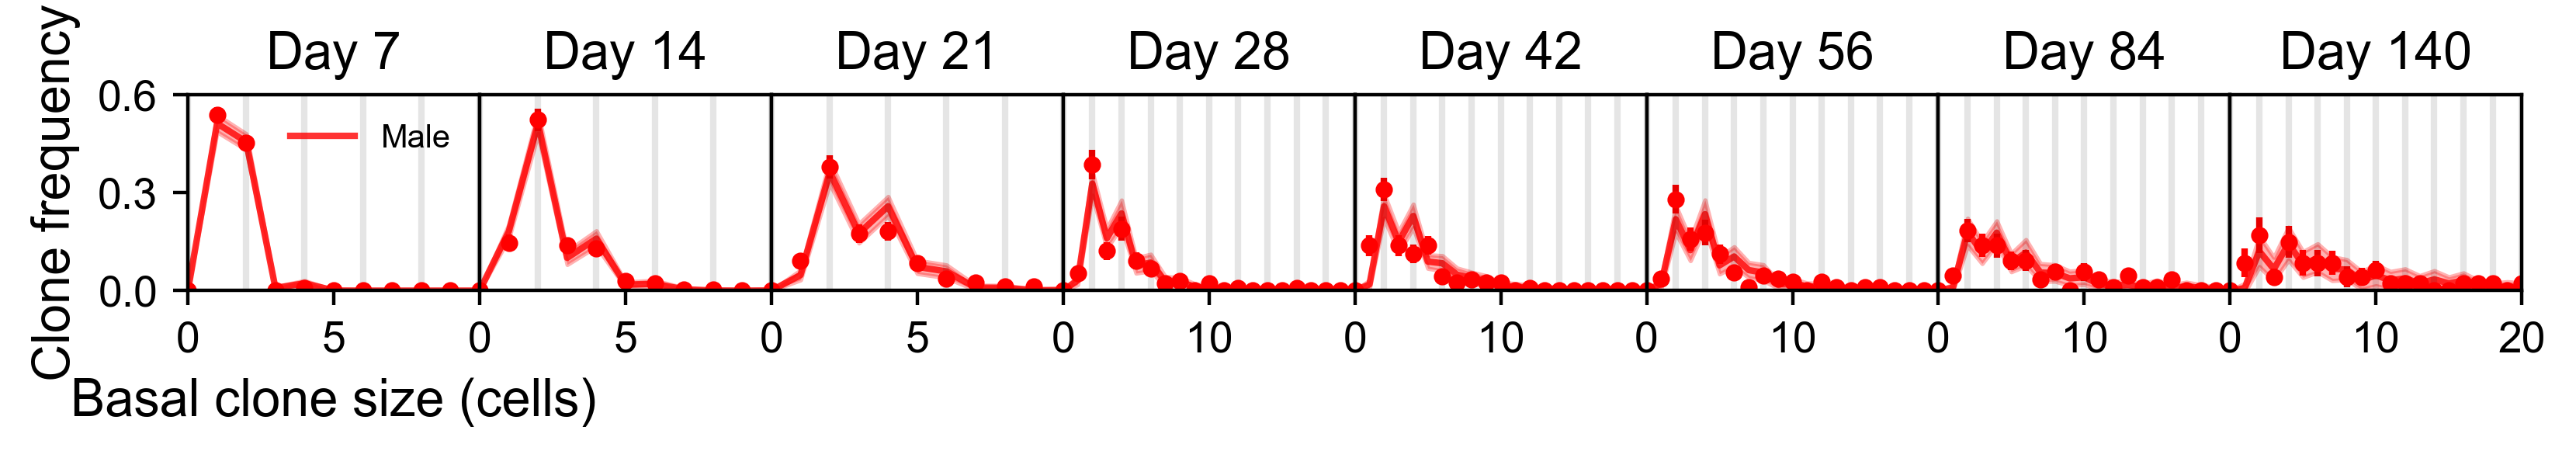

Already cropped


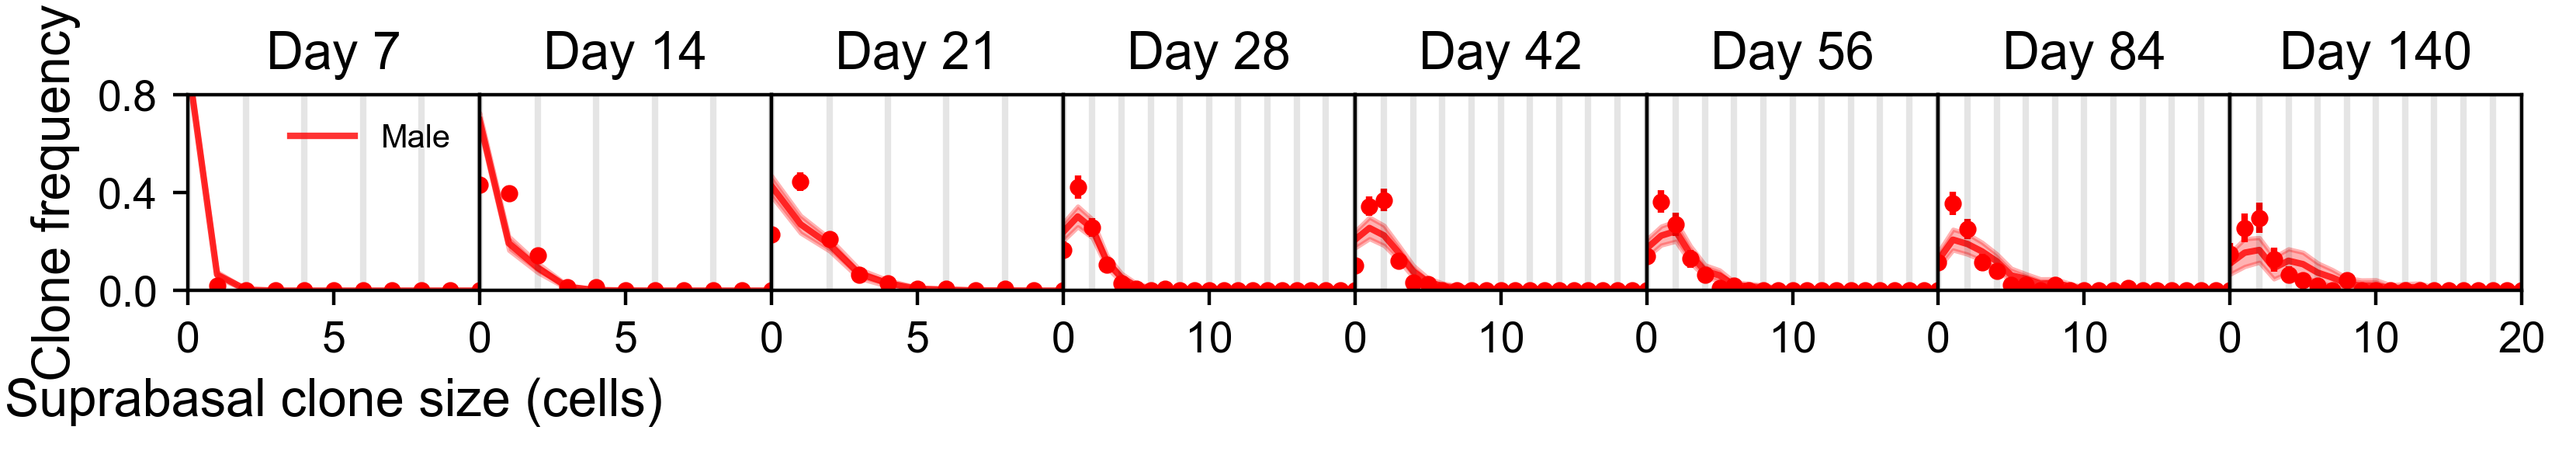

Already cropped


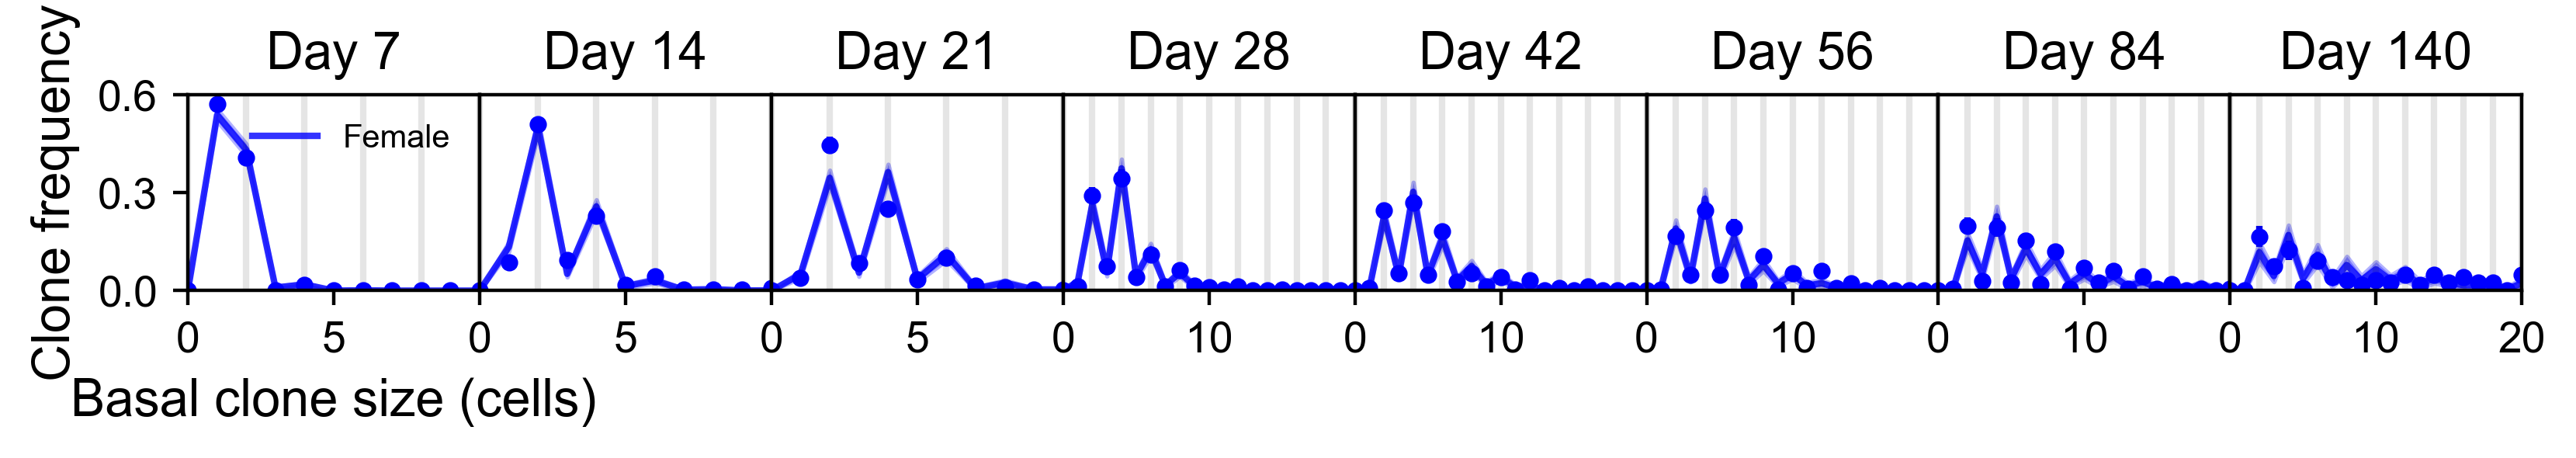

Already cropped


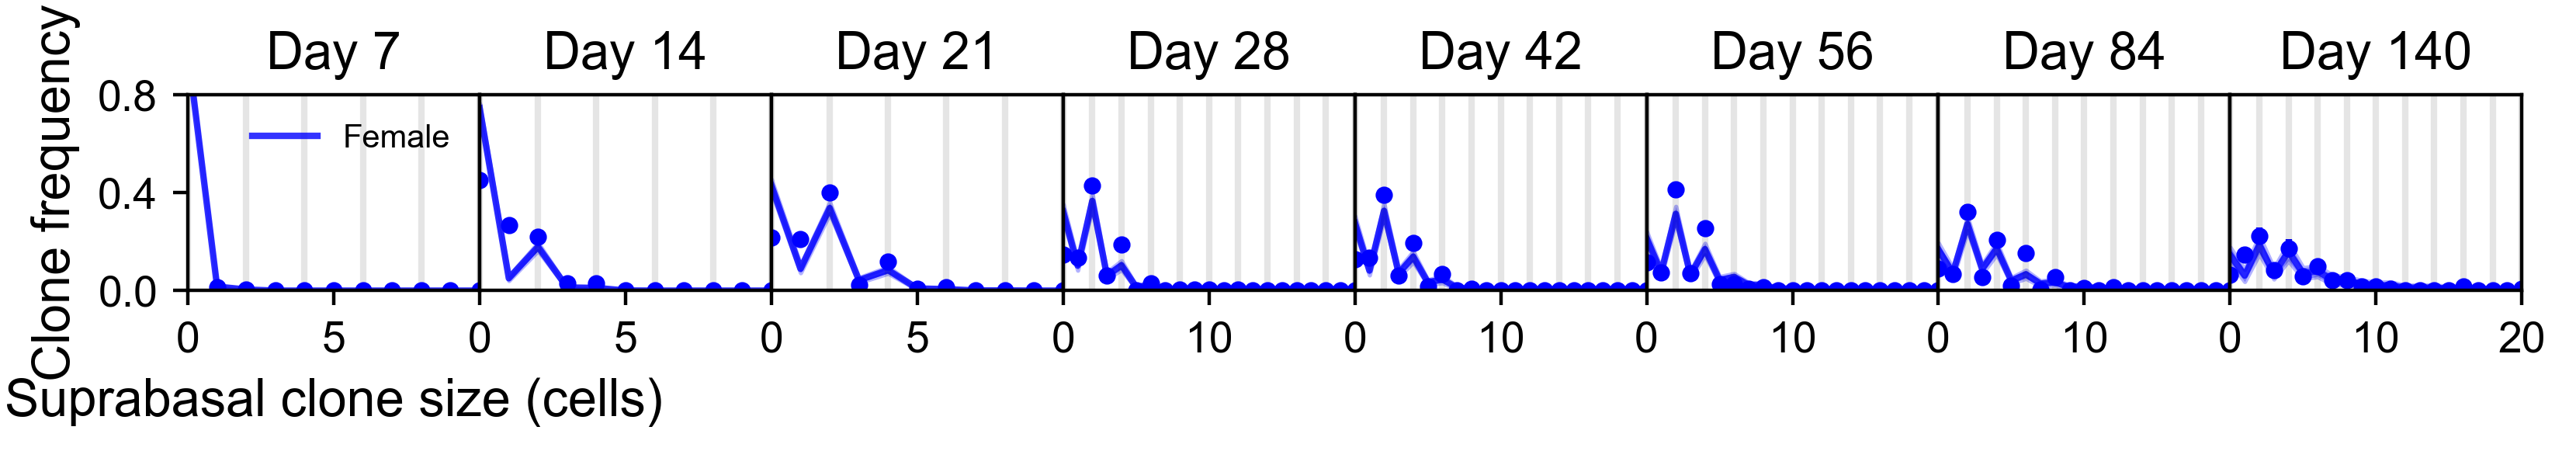

In [ ]:
fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male'}
figfolder = 'Fig3_two_progenitor/F3_'


sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = None, maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 10, 20, 20, 20, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2))    
axs[0].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}{sex}basal_pdf_short_thesis.pdf', dpi = 300)     
plt.show()


axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = None, maxbin = 25, cdf = False, 
                   xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10, 10, 10, 20, 20, 20, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 21, 2))    
axs[0].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}{sex}supra_pdf_short_thesis.pdf', dpi = 300)     
plt.show()



sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = None, maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 10, 20, 20, 20, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2))    
axs[0].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}{sex}basal_pdf_short_thesis.pdf', dpi = 300)     
plt.show()


axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = None, maxbin = 25, cdf = False, 
                   xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10, 10, 10, 20, 20, 20, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 21, 2))  
axs[0].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}{sex}supra_pdf_short_thesis.pdf', dpi = 300)     
plt.show()


Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped
Already cropped


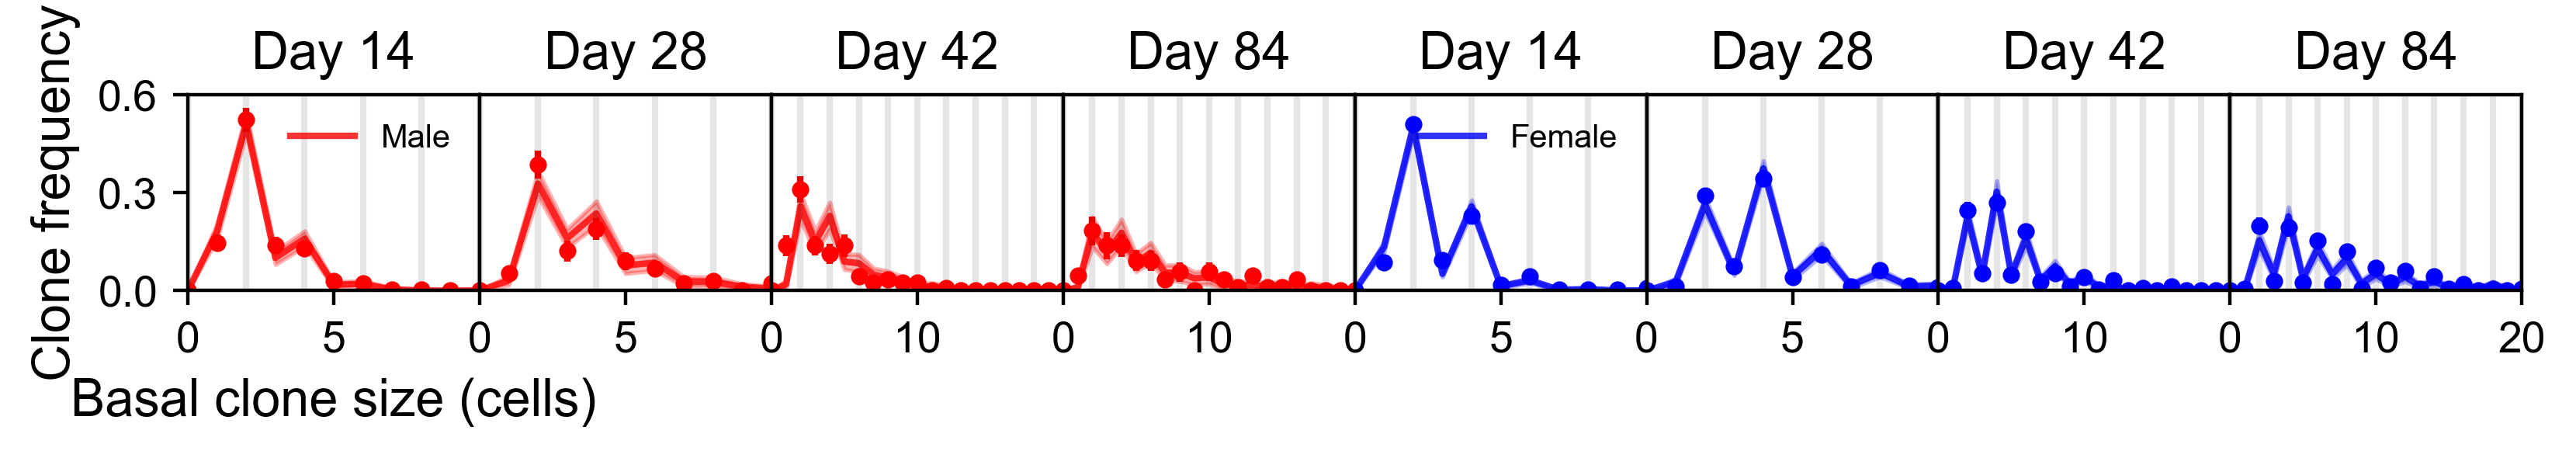

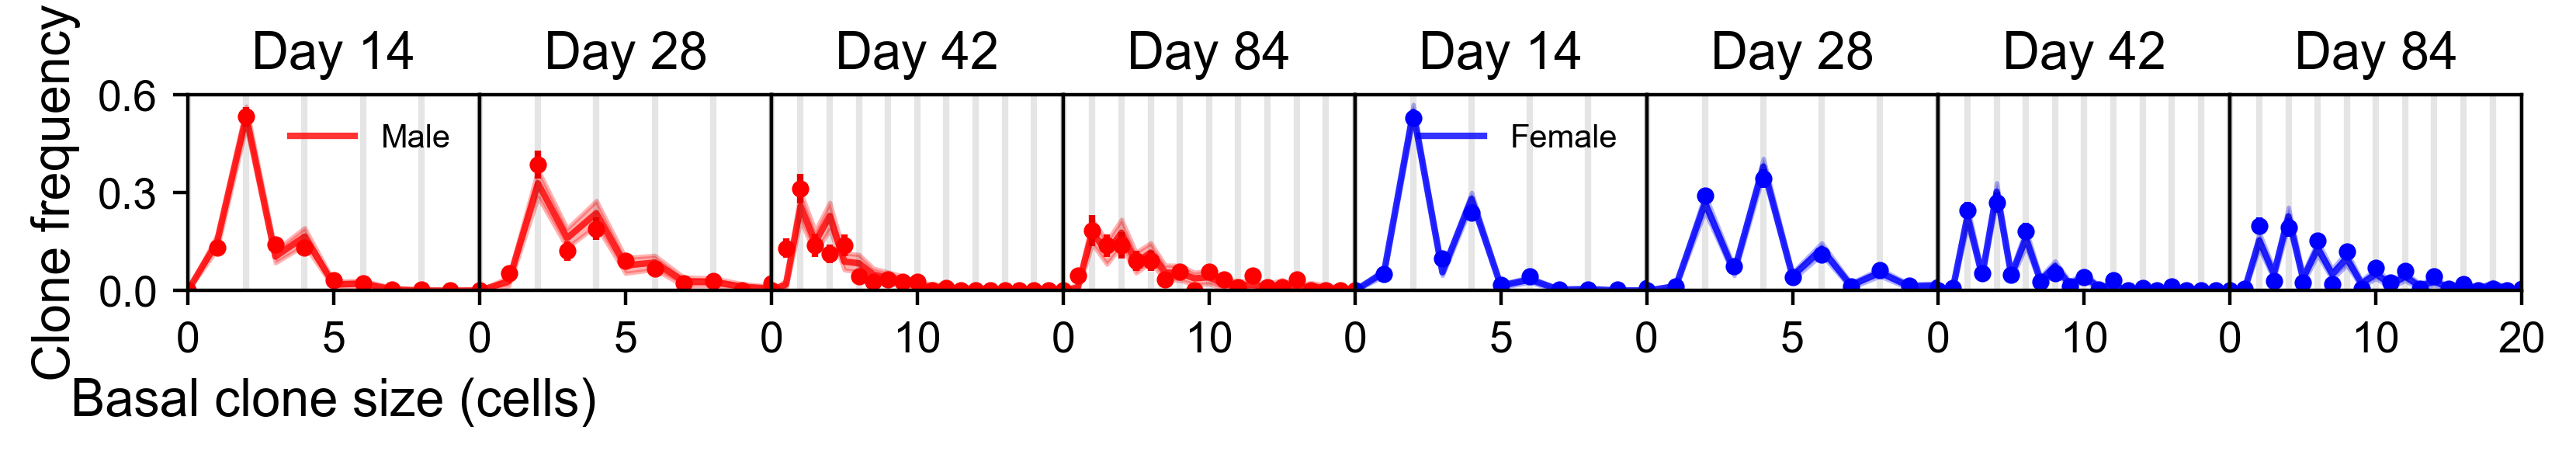

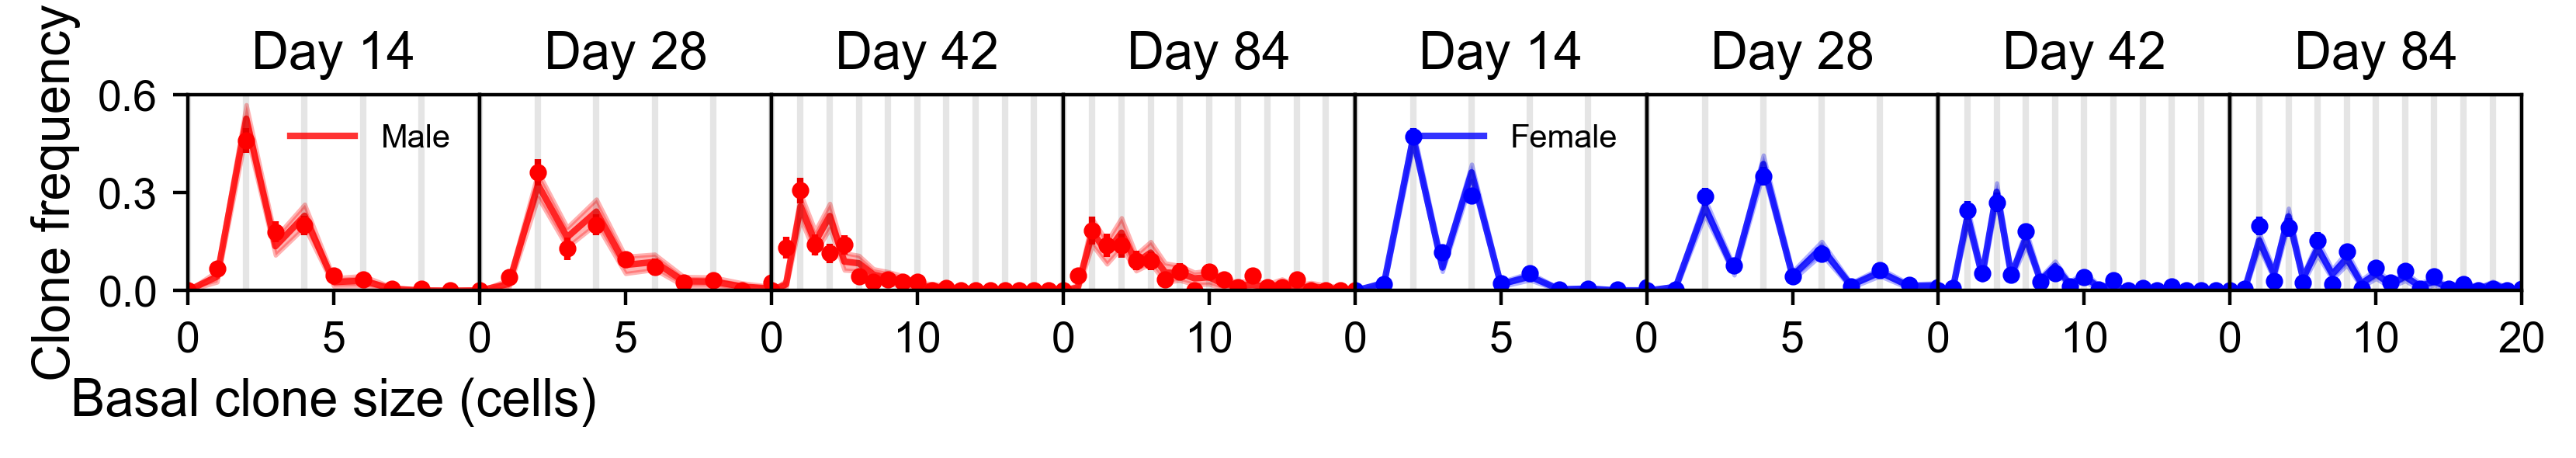

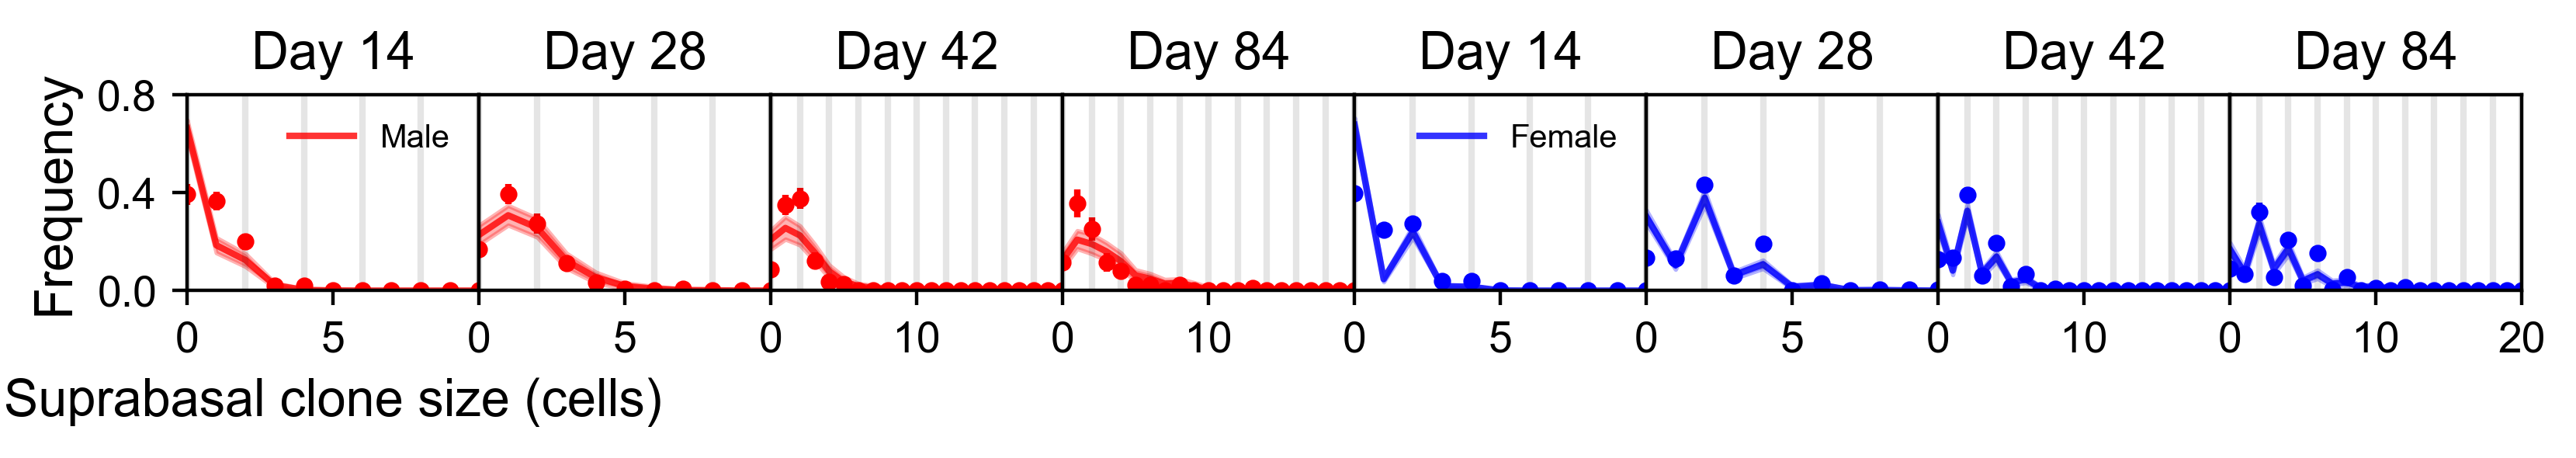

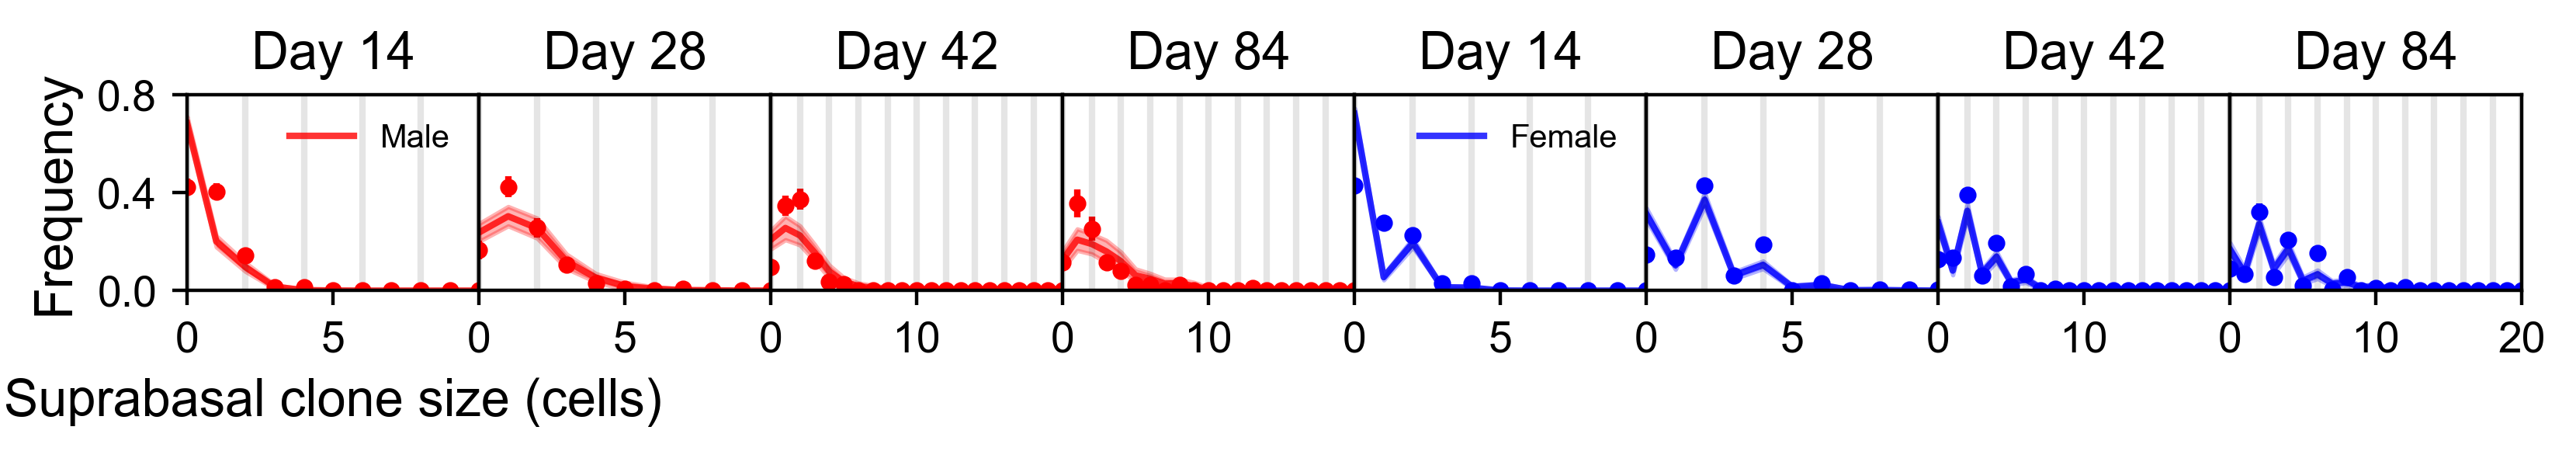

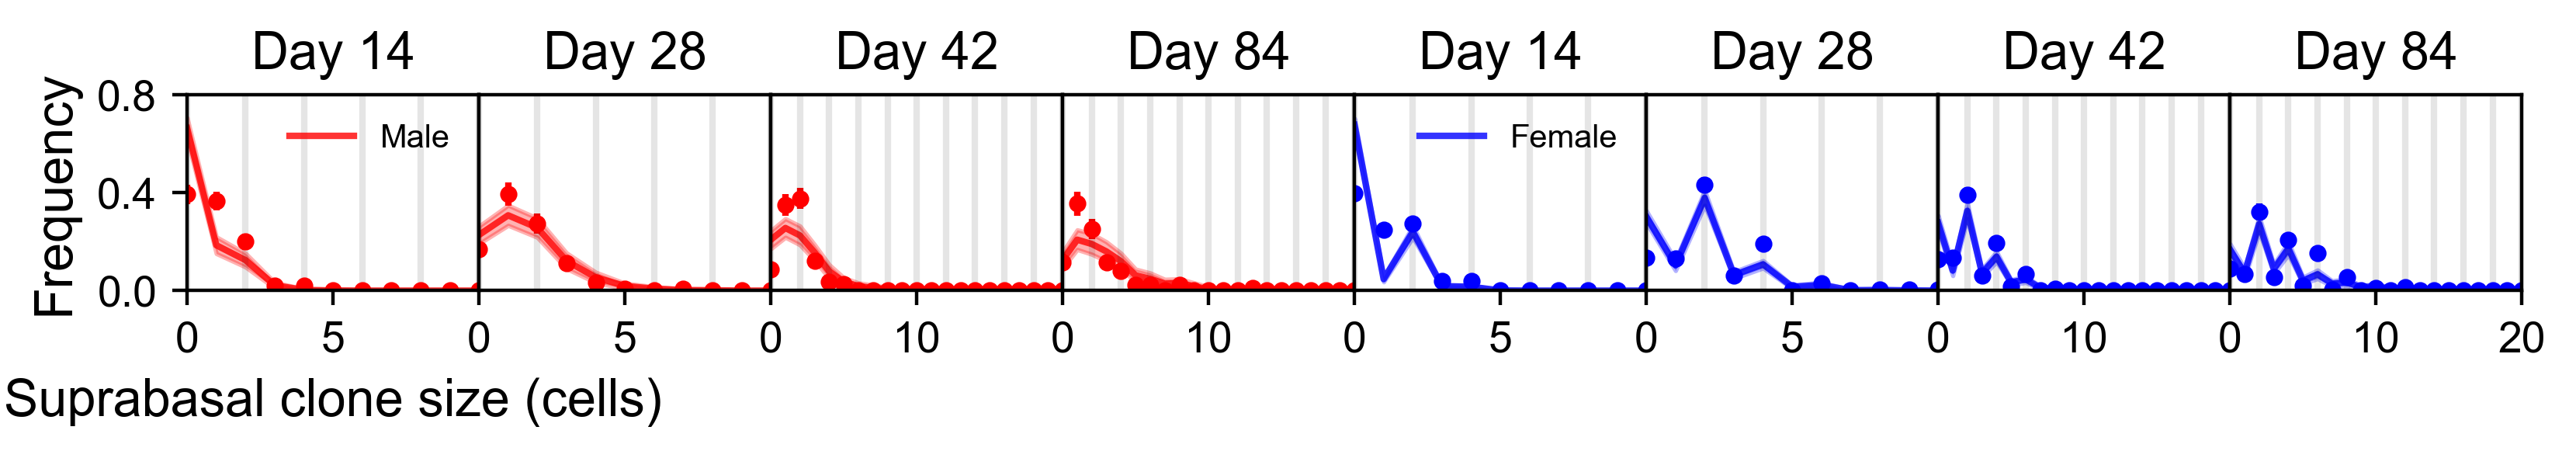

In [ ]:
fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male'}
figfolder = 'Fig3_two_progenitor/F3_'

sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2))    

sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
#plt.savefig(f'Figures/{figfolder}basal_pdf_short_thesis.pdf', dpi = 300)     



sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2))    

sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
#plt.savefig(f'Figures/{figfolder}S2_basal_pdf_short_thesis.pdf', dpi = 300)  


sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S4like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2))    

sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('S4like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
#plt.savefig(f'Figures/{figfolder}S4_basal_pdf_short_thesis.pdf', dpi = 300)  



sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S4like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                     yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2))  
sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S4like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
#plt.savefig(f'Figures/{figfolder}supra_pdf_short_thesis.pdf', dpi = 300)   


sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                     yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2))  
sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
#plt.savefig(f'Figures/{figfolder}S2_supra_pdf_short_thesis.pdf', dpi = 300)   


sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S4like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                     yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2))  
sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S4like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
#plt.savefig(f'Figures/{figfolder}S4_supra_pdf_short_thesis.pdf', dpi = 300)   

Already cropped
Already cropped
Already cropped
Already cropped


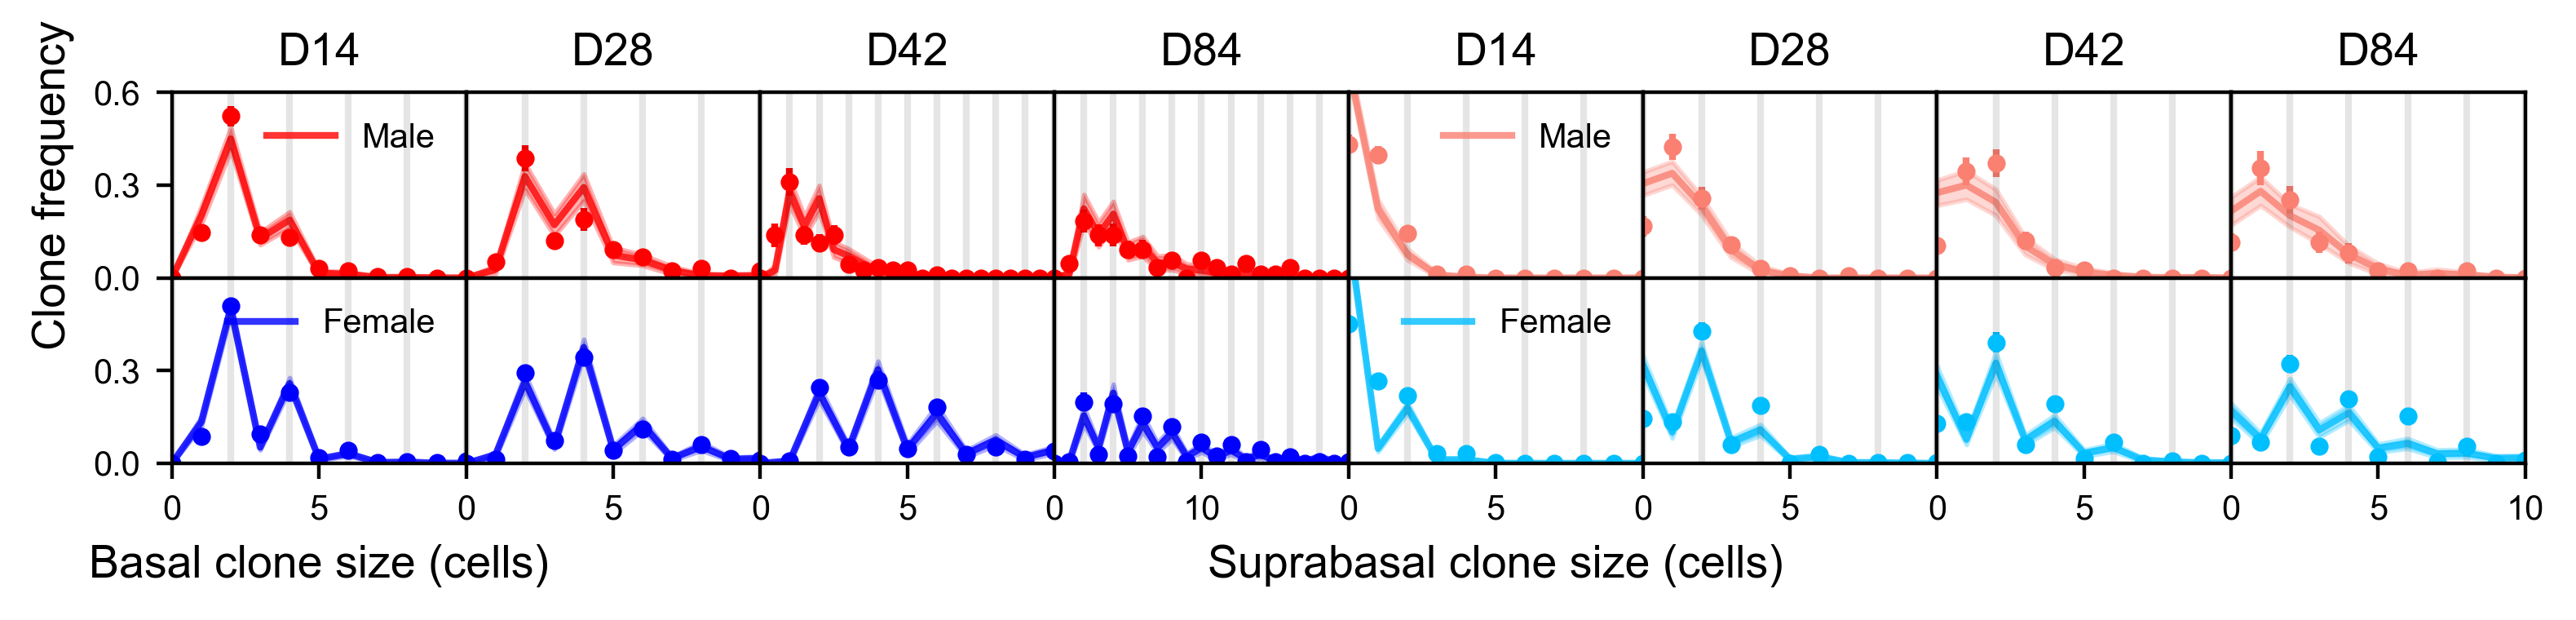

In [16]:
fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male'}
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}

figfolder = 'Fig3_two_progenitor/F3_'

ys = 1.0
iw = 1.0

sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone frequency', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), nrows = 2)    

sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 20],
                ylabel = 'Clone fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 8, nrows  = 2)  



sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Supra clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 10], subplot_axs = axs,
                ylabel = 'Clone frequency', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), x0 = 4, nrows = 2)    

sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Supra clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10, 10, 10, 10],
                ylabel = 'Clone fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 12, nrows = 2)  
#axs[1,0].set_xlabel('Basal clone size (cells)')
axs[1,0].set_xlabel('Basal clone size (cells)')
axs[1,4].set_xlabel('Suprabasal clone size (cells)')
axs[0,0].legend(loc='upper right', frameon=False)
axs[1,0].legend(loc='upper right', frameon=False)
axs[0,4].legend(loc='upper right', frameon=False)
axs[1,4].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}_all_pdfs_flat.pdf', dpi = 300)   

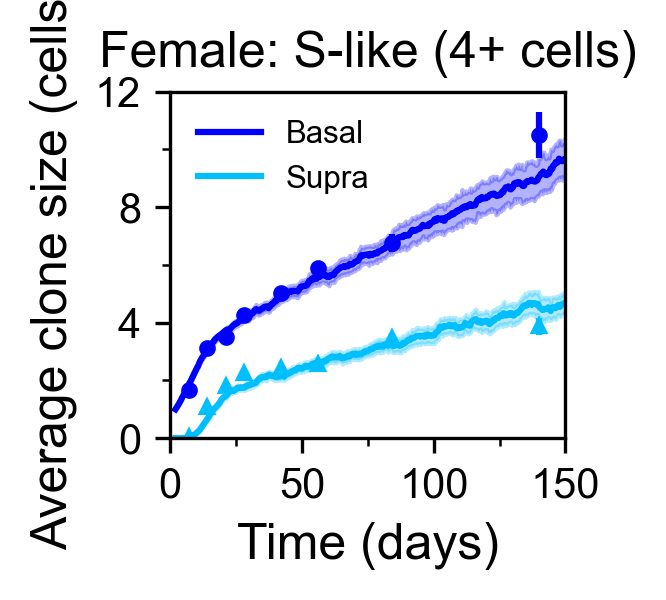

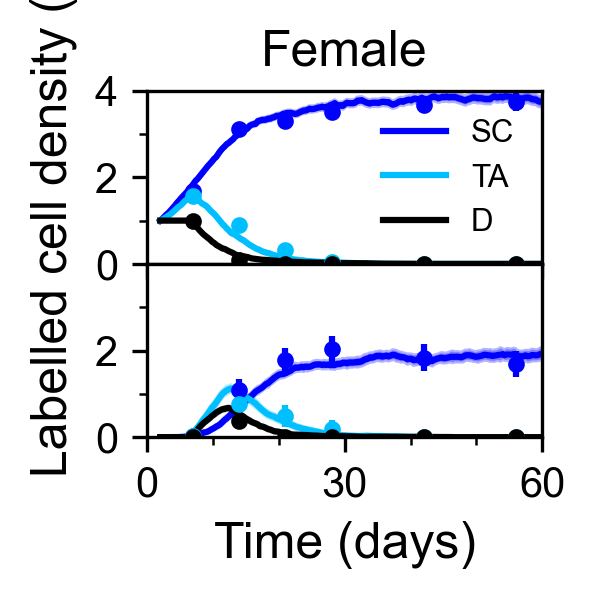

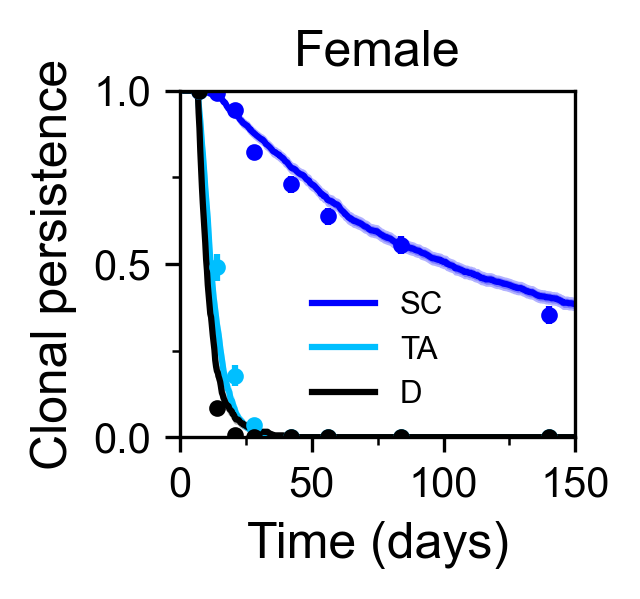

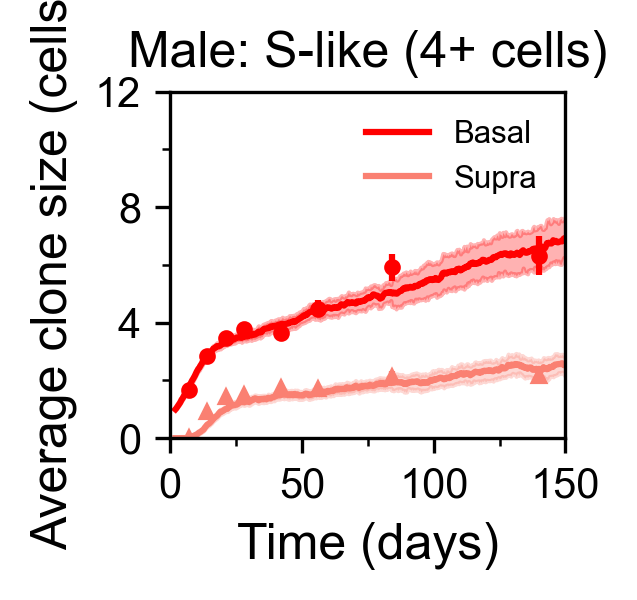

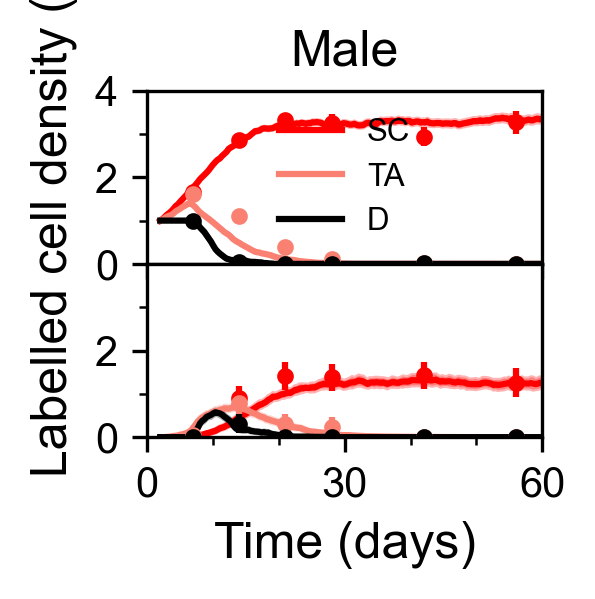

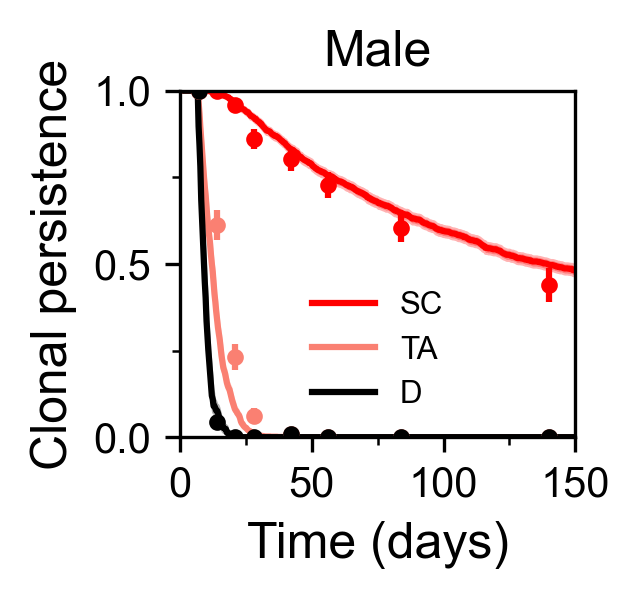

In [51]:
fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male'}

for sex in  ['F','M']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets_full[sex]
    sdt = sim_datasets[sex]

    sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}


    plt.figure(figsize = (1.7,1.5), dpi = 300)  
    ds.plot_quantity('S4like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'Basal', color = cols[sex], xfmt = 'o', sfmt = '-')
    ds.plot_quantity('S4like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'Supra', color = sec_cols[sex], xfmt = '^', sfmt = '-')
    plt.xlim([0,150])
    plt.ylim([0,12])
    plt.yticks(np.arange(0, 13, 4))
    plt.yticks(np.arange(0, 13, 2), minor = True)
    plt.xticks(np.arange(0, 151, 50))
    plt.xticks(np.arange(0, 151, 25), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex] + ': S-like (4+ cells)')
    plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_S4.pdf', dpi = 300)
    plt.show() 


    plt.figure(figsize = (1.7,1.5), dpi = 300)
    plt.subplot(2,1,1)
    ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

    ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
    ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
    plt.ylim([0,4])
    plt.yticks(np.arange(0, 5, 2))
    plt.yticks(np.arange(0, 5, 1), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex])
    plt.xlim([0,60])
    plt.xticks([0,60], minor = True)
    plt.xticks([0,60], minor = False, alpha = 0.0)
    #plt.xticks([])
    plt.xlabel('  ')

    #plt.show()
    plt.subplot(2,1,2)
    ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex], nolegend = True)
    ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex], nolegend = True)           
    ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Supra labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k', nolegend = True)    
    plt.ylim([0,4])
    plt.yticks(np.arange(0, 4, 2))
    plt.yticks(np.arange(0, 4, 1), minor = True)
    plt.xlim([0,60])
    plt.xticks(np.arange(0, 61, 30))
    plt.xticks(np.arange(0, 61, 10), minor = True)
    plt.ylabel('')
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout()

    plt.savefig(f'Figures/{figfolder}{sexname[sex]}_labelled_cell_density.pdf', dpi = 300)
    plt.show()             



    plt.figure(figsize = (1.7,1.5), dpi = 300)
    ds.plot_quantity('S4like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])
    ds.plot_quantity('CPlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])
    ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
    #plt.title(fullsex[sex])
    plt.xlim([0,150])
    plt.ylim([0,1])
    plt.yticks(np.arange(0, 1.1, 0.5))
    plt.yticks(np.arange(0, 1.1, 0.25), minor = True)
    plt.xticks(np.arange(0, 151, 50))
    plt.xticks(np.arange(0, 151, 25), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex])
    plt.savefig(f'Figures/{figfolder}{sexname[sex]}_persistence.pdf', dpi = 300)
    plt.show() 

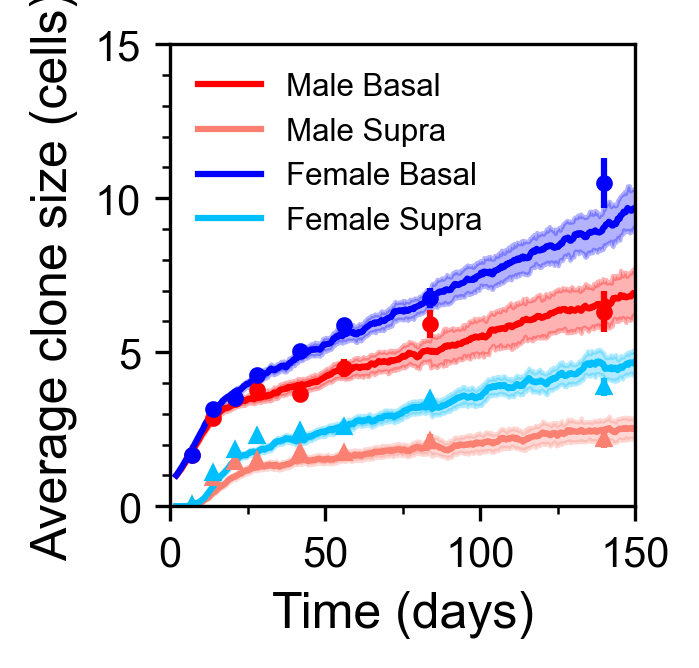

In [13]:
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}

plt.figure(figsize = (8.0/4,2.0), dpi = 300)  
sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

ds.plot_quantity('S4like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'Male Basal', color = cols[sex], xfmt = 'o', sfmt = '-')
ds.plot_quantity('S4like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'Male Supra', color = sec_cols[sex], xfmt = '^', sfmt = '-')

sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

ds.plot_quantity('S4like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'Female Basal', color = cols[sex], xfmt = 'o', sfmt = '-')
ds.plot_quantity('S4like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'Female Supra', color = sec_cols[sex], xfmt = '^', sfmt = '-')


plt.xlim([0,150])
plt.ylim([0,15])
plt.yticks(np.arange(0, 16, 5))
plt.yticks(np.arange(0, 16, 1), minor = True)
plt.xticks(np.arange(0, 151, 50))
plt.xticks(np.arange(0, 151, 25), minor = True)
plt.legend(frameon = False)
#plt.title('SC-like (4+ cells)')
plt.savefig(f'Figures/{figfolder}_av_size_S4.pdf', dpi = 300)
plt.show() 



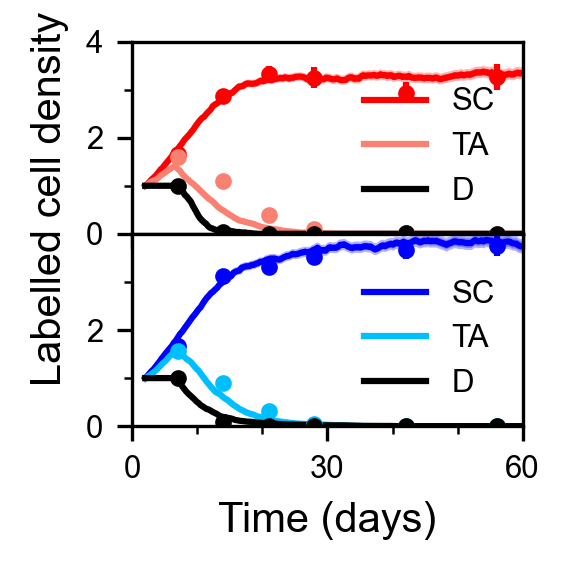

In [ ]:
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}
figfolder = 'Fig3_two_progenitor/F3_'


plt.figure(figsize = (2.0,2.0), dpi = 300)
plt.subplot(2,1,1)
sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
plt.ylim([0,4])
plt.yticks(np.arange(0, 5, 2))
plt.yticks(np.arange(0, 5, 1), minor = True)
plt.legend(frameon = False)
plt.xlim([0,60])
plt.xticks([0,60], minor = True)
plt.xticks([0,60], minor = False, alpha = 0.0)
#plt.xticks([])
plt.xlabel('')

#plt.show()
plt.subplot(2,1,2)
sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
plt.ylim([0,4])
plt.yticks(np.arange(0, 4, 2))
plt.yticks(np.arange(0, 4, 1), minor = True)
plt.xlim([0,60])
plt.xticks(np.arange(0, 61, 30))
plt.xticks(np.arange(0, 61, 10), minor = True)
plt.ylabel(' ')

plt.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0)

plt.savefig(f'Figures/{figfolder}_labelled_cell_density.pdf', dpi = 300)
plt.show()    

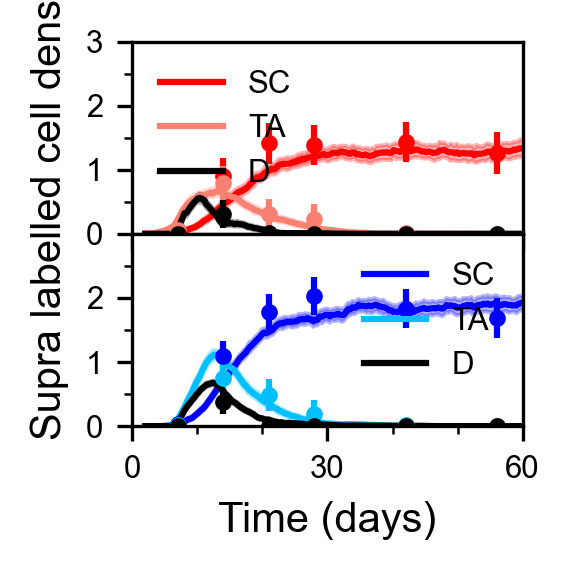

In [11]:
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}
figfolder = 'Fig3_two_progenitor/F3_'


plt.figure(figsize = (2.0,2.0), dpi = 300)
plt.subplot(2,1,1)
sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Supra labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
plt.ylim([0,3])
plt.yticks(np.arange(0, 4, 1))
plt.yticks(np.arange(0, 3.5, 0.5), minor = True)
plt.legend(frameon = False)
plt.xlim([0,60])
plt.xticks([0,60], minor = True)
plt.xticks([0,60], minor = False, alpha = 0.0)
#plt.xticks([])
plt.xlabel('')

#plt.show()
plt.subplot(2,1,2)
sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                ylabel = 'Labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
plt.ylim([0,3])
plt.yticks(np.arange(0, 3, 1))
plt.yticks(np.arange(0, 3.1, 0.5), minor = True)
plt.xlim([0,60])
plt.xticks(np.arange(0, 61, 30))
plt.xticks(np.arange(0, 61, 10), minor = True)
plt.ylabel(' ')

plt.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0)

plt.savefig(f'Figures/{figfolder}_supra_labelled_cell_density.pdf', dpi = 300)
plt.show()    

1
2
3
7
8
9
4
5
6
10
11
12


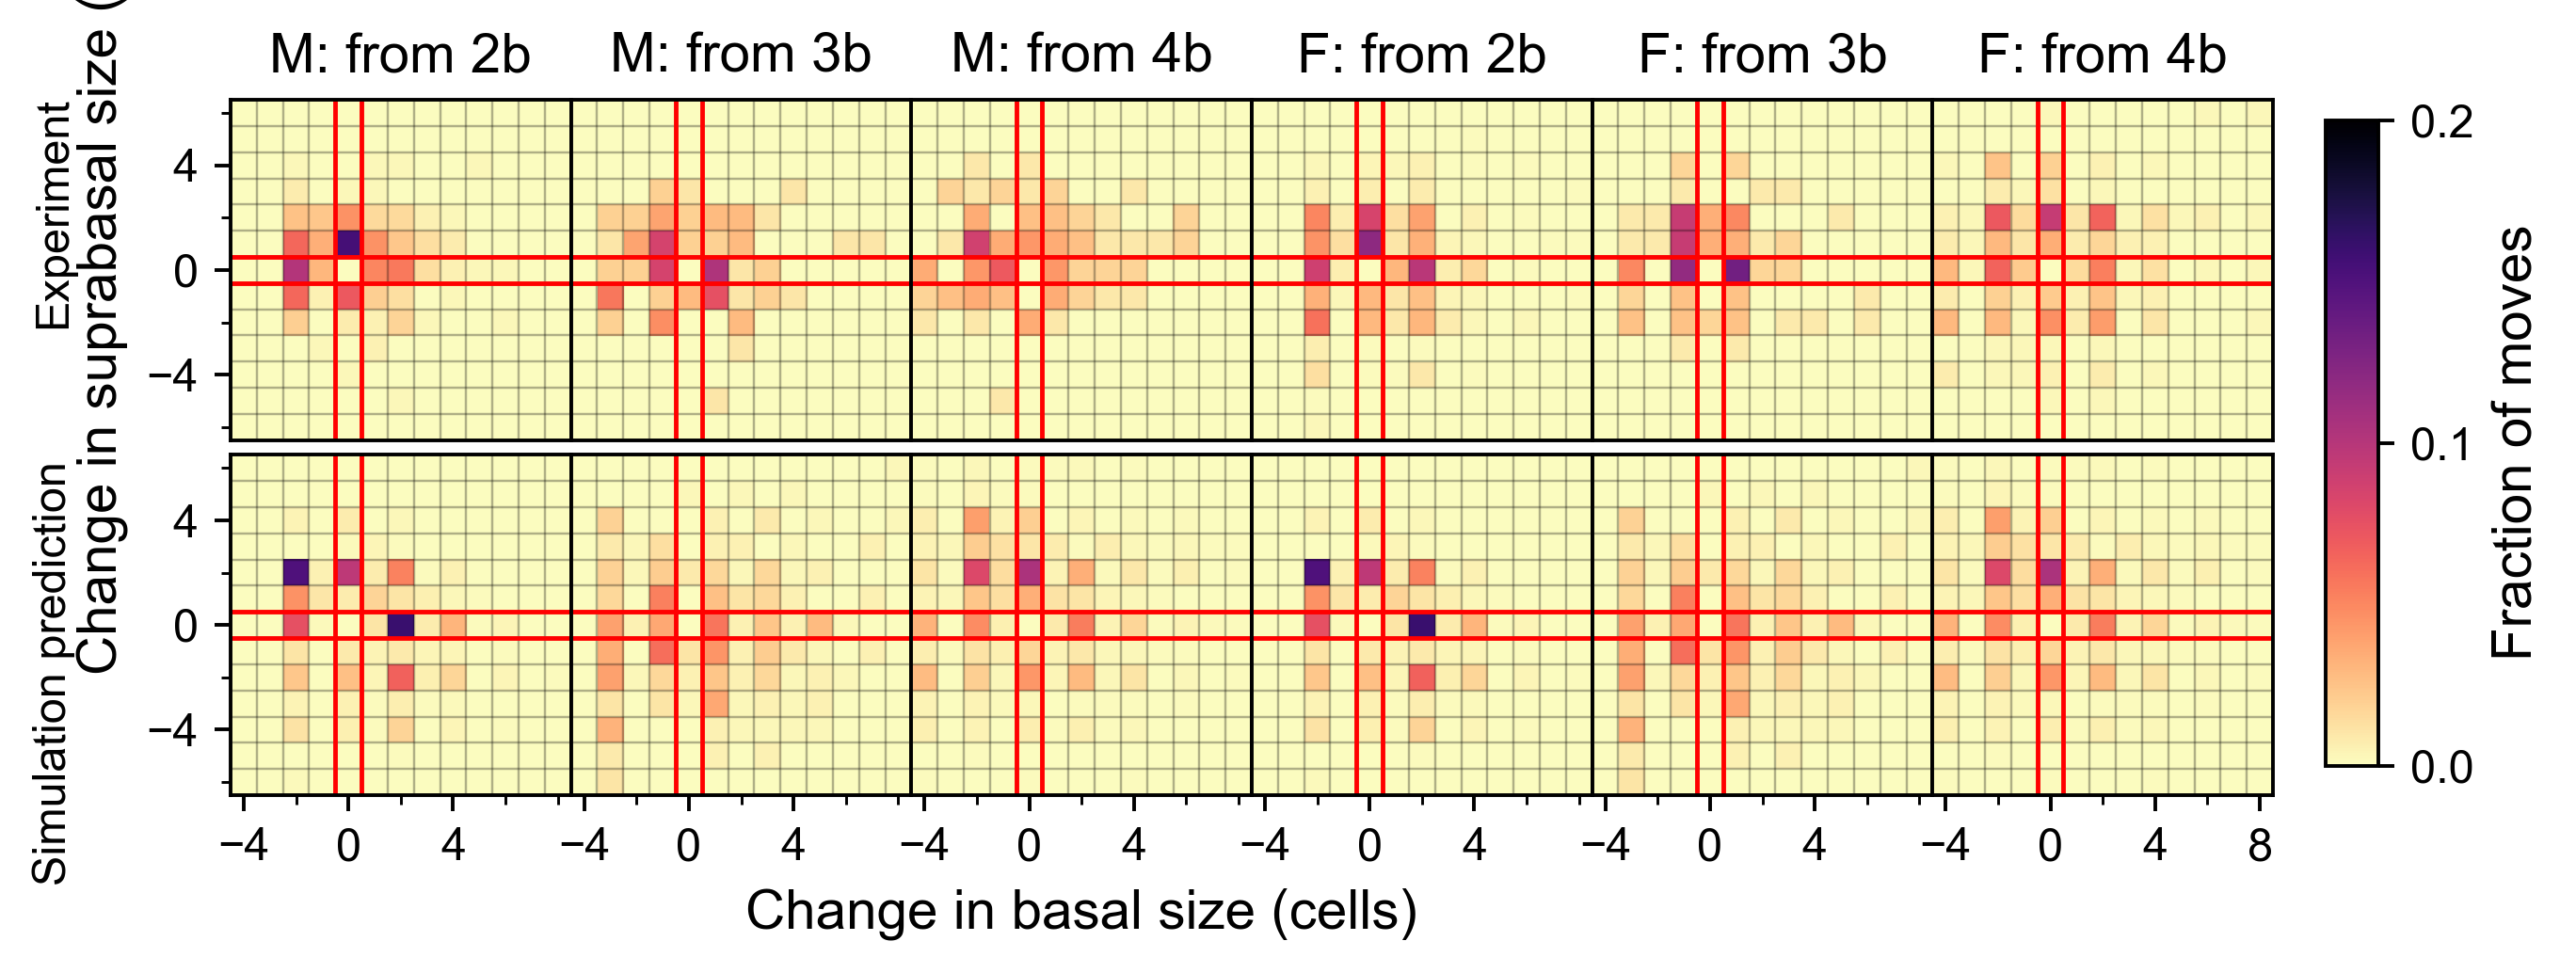

In [36]:
def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, 
               tstart = 0, plot = True, tit_prefix = '', vmax = None, cbar = True, labels = True):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'from ' + str(init_bas) + 'b'
    elif init_bas is None and init_sup is not None:
        tit = 'from ' + str(init_sup) + 's'
    elif init_bas is not None and init_sup is not None:
        tit = 'from (' + str(init_bas) + 'b,' + str(init_sup) + 's)'
    
    tit = tit_prefix + tit
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 90] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                #print(mb,ms, allmoves[:,mb,ms])
                continue


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]
    
    allmoves2[: -max_move,-max_move] = 0

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            #toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], 
                   origin='lower', cmap = 'magma_r', vmin = 0.0, vmax = vmax) #PuRd#magma_r
        if labels:
            plt.xlabel('Change in basal size (cells)')
            plt.ylabel('Change in suprabasal size (cells)')
        if cbar:
            if use_log:
                plt.colorbar(label = 'log2(# moves)')
            else:
                plt.colorbar(label = 'Fraction of moves')#, ticks = [0, 0.05, 0.1, 0.15])
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,4))
        plt.yticks(np.arange(-max_move,max_move+1,4))
        plt.xticks(np.arange(-max_move,max_move+1,2), minor = True)
        plt.yticks(np.arange(-max_move,max_move+1,2), minor = True)        
        plt.title(tit)
        
        if not labels:
            plt.xticks([])
            plt.yticks([])
    
    return allmoves


def make_axis(max_move, i, xlabel_loc = 2, ncols = 3, j = 0, nrows = 1):
    xticks = np.arange(-max_move,max_move+1,2)
    if (i-1) % ncols > 0:
        plt.yticks([])
        plt.yticks([], minor = True)
        plt.ylabel('')
    else:
        plt.yticks(xticks[::2])
        plt.yticks(xticks, minor = True)
    
    if nrows > 1:
        if j > 0:
            plt.ylabel('')

    if j == (nrows - 1):
        if (i - 1) % ncols != xlabel_loc:
            plt.xlabel('')

        xticks = np.arange(-max_move,max_move+1,2)
        plt.xticks(xticks, minor = True) 
        if (i - 1) % ncols < (ncols - 1):
            xticks = xticks[xticks < 8]
        plt.xticks(xticks[::2])  
    else:
        plt.xticks([])
        plt.xlabel('')



sex = 'M'


plt.figure(figsize = (8,2.8), dpi = 350)
max_move = 20
i = 1

j = 0
for sex in ['M', 'F']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets[sex]
    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,i+3*j)
        print(i+3*j)
        ax = plt.gca()
        plot_moves(exp_data.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex}: ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, i+3*j, 2, 6, 0, 2)
        plt.xlim([-4 - 0.5,8.5])
        plt.ylim([-6.5,6.5])
        plt.xticks([])
        plt.xticks([], minor = True)
        plt.xlabel('')
        i += 1  

    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,6+i+3*j)
        print(6+i+3*j)
        ax = plt.gca()
        plot_moves(sdt.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex} ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, 6+i+3*j, 2, 6, 1, 2)
        plt.xlim([-4 - 0.5,8.5])
        plt.ylim([-6.5,6.5])
        plt.title('')
        plt.ylabel('')
        i += 1
    j += 1
    
#plt.tight_layout()
plt.subplots_adjust(wspace=0.0, hspace=0)
fig = plt.gcf()
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
mappable = plt.cm.ScalarMappable(cmap='magma_r', norm=plt.Normalize(vmin=0, vmax=0.2))
cbar = fig.colorbar(mappable, cax=cbar_ax, ticks = [0,0.1,0.2])
cbar.set_label('Fraction of moves')

fig.text(0.05, 0.75, 'Experiment', va='center', rotation='vertical', fontsize=10)
fig.text(0.05, 0.25, 'Simulation prediction', va='center', rotation='vertical', fontsize=10)
plt.savefig(f'Figures/Fig3_two_progenitor/F3_transitions.pdf', dpi = 300)
plt.show()



1
7


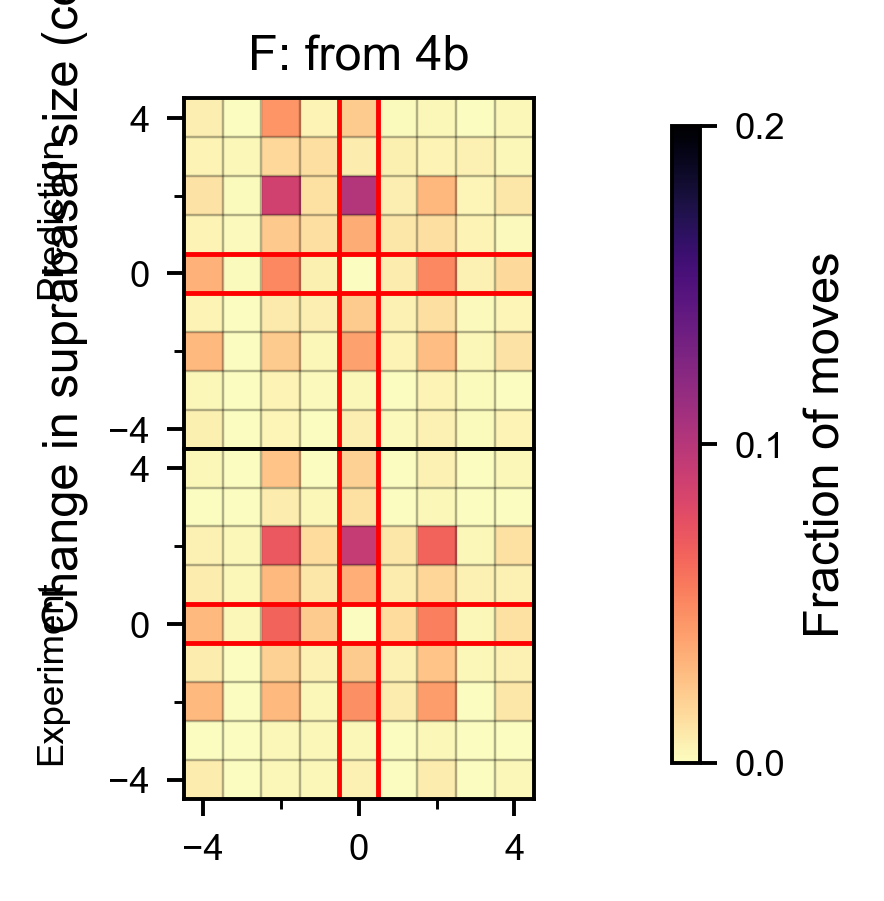

In [24]:
def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, 
               tstart = 0, plot = True, tit_prefix = '', vmax = None, cbar = True, labels = True):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'from ' + str(init_bas) + 'b'
    elif init_bas is None and init_sup is not None:
        tit = 'from ' + str(init_sup) + 's'
    elif init_bas is not None and init_sup is not None:
        tit = 'from (' + str(init_bas) + 'b,' + str(init_sup) + 's)'
    
    tit = tit_prefix + tit
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 90] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                #print(mb,ms, allmoves[:,mb,ms])
                continue


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]
    
    allmoves2[: -max_move,-max_move] = 0

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            #toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], 
                   origin='lower', cmap = 'magma_r', vmin = 0.0, vmax = vmax) #PuRd#magma_r
        if labels:
            plt.xlabel('Change in basal size (cells)')
            plt.ylabel('Change in suprabasal size (cells)')
        if cbar:
            if use_log:
                plt.colorbar(label = 'log2(# moves)')
            else:
                plt.colorbar(label = 'Fraction of moves')#, ticks = [0, 0.05, 0.1, 0.15])
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,4))
        plt.yticks(np.arange(-max_move,max_move+1,4))
        plt.xticks(np.arange(-max_move,max_move+1,2), minor = True)
        plt.yticks(np.arange(-max_move,max_move+1,2), minor = True)        
        plt.title(tit)
        
        if not labels:
            plt.xticks([])
            plt.yticks([])
    
    return allmoves


def make_axis(max_move, i, xlabel_loc = 2, ncols = 3, j = 0, nrows = 1):
    xticks = np.arange(-max_move,max_move+1,2)
    if (i-1) % ncols > 0:
        plt.yticks([])
        plt.yticks([], minor = True)
        plt.ylabel('')
    else:
        plt.yticks(xticks[::2])
        plt.yticks(xticks, minor = True)
    
    if nrows > 1:
        if j > 0:
            plt.ylabel('')

    if j == (nrows - 1):
        if (i - 1) % ncols != xlabel_loc:
            plt.xlabel('')

        xticks = np.arange(-max_move,max_move+1,2)
        plt.xticks(xticks, minor = True) 
        if (i - 1) % ncols < (ncols - 1):
            xticks = xticks[xticks < 8]
        plt.xticks(xticks[::2])  
    else:
        plt.xticks([])
        plt.xlabel('')



sex = 'M'


plt.figure(figsize = (2,2.6), dpi = 350)
max_move = 20
i = 1

j = 0
for sex in ['F']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets[sex]
    i = 1
    for b in [4]:
        plt.subplot(2,1,1)
        print(i+3*j)
        ax = plt.gca()
        plot_moves(sdt.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex}: ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, i+3*j, 2, 6, 0, 2)
        plt.xlim([-4 - 0.5,4.5])
        plt.ylim([-4.5,4.5])
        plt.xticks([])
        plt.xticks([], minor = True)
        plt.xlabel('')
        i += 1  

    i = 1
    for b in [4]:
        plt.subplot(2,1,2)
        print(6+i+3*j)
        ax = plt.gca()
        plot_moves(exp_data.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex} ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, 6+i+3*j, 2, 6, 1, 2)
        plt.xlim([-4 - 0.5,4.5])
        plt.ylim([-4.5,4.5])
        plt.title('')
        plt.ylabel('')
        i += 1
    j += 1
    
#plt.tight_layout()
plt.subplots_adjust(wspace=0.0, hspace=0)
fig = plt.gcf()
cbar_ax = fig.add_axes([0.96, 0.15, 0.04, 0.7])  # [left, bottom, width, height]
mappable = plt.cm.ScalarMappable(cmap='magma_r', norm=plt.Normalize(vmin=0, vmax=0.2))
cbar = fig.colorbar(mappable, cax=cbar_ax, ticks = [0,0.1,0.2])
cbar.set_label('Fraction of moves')

fig.text(0.05, 0.25, 'Experiment', va='center', rotation='vertical', fontsize=7.5)
fig.text(0.05, 0.75, 'Prediction', va='center', rotation='vertical', fontsize=7.5)
plt.savefig(f'Figures/Fig3_two_progenitor/F3_transitions_F.pdf', dpi = 300)
plt.show()



[0, np.float64(7.0), np.float64(14.0), np.float64(21.0), np.float64(28.0), np.float64(42.0), np.float64(56.0), np.float64(84.0), np.float64(140.0)]
[0, np.float64(7.0), np.float64(14.0), np.float64(21.0), np.float64(28.0), np.float64(42.0), np.float64(56.0), np.float64(84.0), np.float64(140.0)]
[0, np.float64(7.0), np.float64(14.0), np.float64(21.0), np.float64(28.0), np.float64(42.0), np.float64(56.0), np.float64(84.0), np.float64(140.0)]


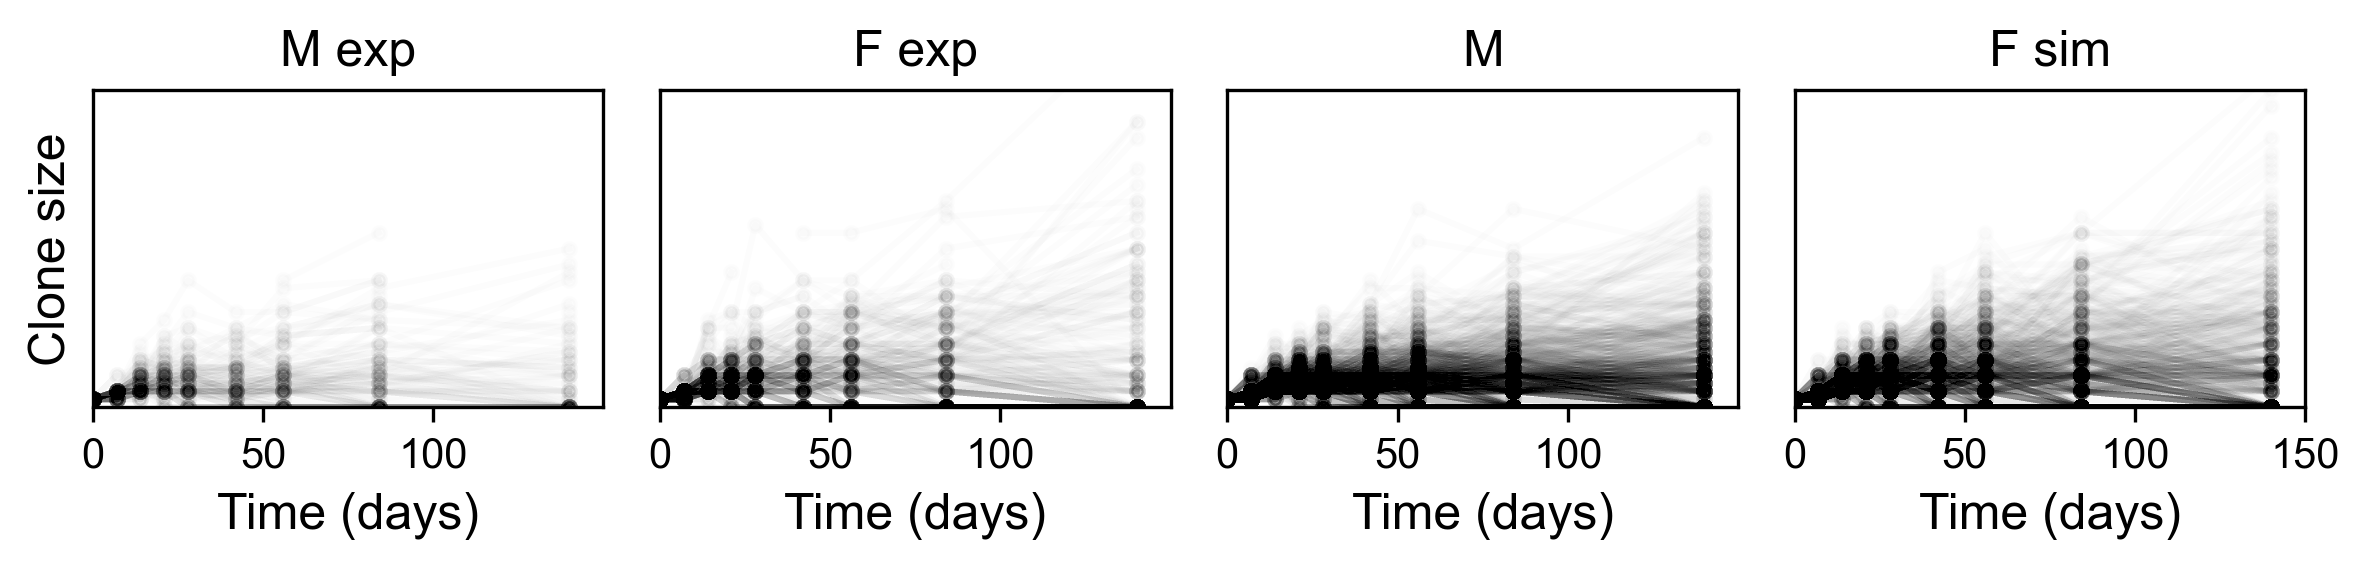

In [35]:
alpha = 0.01

livesize_M = exp_datasets['M'].raw_data['clone_anal'].S4like().live_bas_sb
livesize_F = exp_datasets['F'].raw_data['clone_anal'].S4like().live_bas_sb

ls = livesize_M[:,:,0].astype('float')
ls[ls < 0] = np.nan

ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_datasets['F'].times['basalCS'])
print(times)
nclonesM = ls.shape[0]
plt.figure(figsize=(8,2), dpi = 300)
plt.subplot(1,4,1)
plt.plot(times, ls[:,:].T, 'k-o', alpha = alpha, markersize = 3)
plt.title('M')
plt.xlabel('Time (days)')
plt.ylabel('Clone size')
plt.title('M exp')
plt.ylim([0,40])
plt.yticks([])
plt.xlim([0,150])
plt.xticks(np.arange(0, 150, 50))

ls = livesize_F[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_datasets['F'].times['basalCS'])
nclonesF = ls.shape[0]
print(times)
plt.subplot(1,4,2)
plt.plot(times, ls[:,:].T, 'k-o', alpha = alpha, markersize = 3)
#plt.title('F')
plt.xlabel('Time (days)')
#plt.ylabel('Clone size')
plt.title('F exp')
plt.ylim([0,40])
plt.yticks([])
plt.xlim([0,150])
plt.xticks(np.arange(0, 150, 50))

livesize_M = sim_datasets['M'].raw_data['clone_anal'].S4like().live_bas_sb[nclonesM:,:,:]
livesize_F = sim_datasets['F'].raw_data['clone_anal'].S4like().live_bas_sb[nclonesF:,:,:]

ls = livesize_M[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])

plt.subplot(1,4,3)
plt.plot(times, ls[:,:].T, 'k-o', alpha = alpha, markersize = 3)
plt.title('M')
plt.xlabel('Time (days)')
#plt.ylabel('Clone size')
plt.ylim([0,40])
plt.yticks([])
plt.xlim([0,150])
plt.xticks(np.arange(0, 150, 50))

ls = livesize_F[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_datasets['F'].times['basalCS'])

print(times)
plt.subplot(1,4,4)
plt.plot(times, ls[:,:].T, 'k-o', alpha = alpha, markersize = 3)
plt.title('F sim')
plt.xlabel('Time (days)')
#plt.ylabel('Clone size')
plt.ylim([0,40])
plt.xlim([0,150])
plt.xticks(np.arange(0, 151, 50))
plt.yticks([])
plt.subplots_adjust(wspace=-0.4, hspace=0)
plt.tight_layout()
plt.show()

